# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

# Import bibliotek

In [321]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd



# Wygenerowanie syntetycznych danych

In [322]:
SEED = 20261020
rng = np.random.default_rng(SEED)
print("Ustawiono ziarno RNG: ", SEED)

Ustawiono ziarno RNG:  20261020


# Przygotowanie stałych

In [323]:
LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

# Przygotowanie bazowych danych syntetycznych

## "Katalog"

In [324]:
catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # Średni lokalny popyt (szt./tydz.) na produkty w każdej kategorii
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # Średni turystyczny popyt (szt./tydz.) na produkty w każdej kategorii
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135], # Średnia cena jednostkowa (PLN/szt.) produktów w każdej kategorii
})

In [325]:
# Wylicz typowy (średni) przychód tygodniowy: (lokalni i turyści) * cena jednostkowa
catalog["revenue_avg_pln"] = (
    catalog["demand_loc_base"] + catalog["demand_tur_base"]
) * catalog["price_pln_base"]
display(catalog)

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


### Przygotowywanie funkcji pomocniczych do generowania dancyh tygodniowych

Generowanie popytu lokalnego i turystycznego

In [326]:
def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)

    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur

    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)

    return df[["category", "demand_loc", "demand_tur"]]

Wyliczanie przychodu lokalnego, turystycznego i łącznego

In [327]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(
        catalog[["category", "price_pln_base"]], on="category", how="left"
    )
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pl"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pl"]]

Generowanie danych tygodniowych

In [328]:
def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance, boost_loc, boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

### Wygenerowanie danych tygodniowych

In [335]:
t1 = generate_weekly_data(catalog,rng)
t1 = t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per kategoria (PLN):")
display(t1)
print("Łączny przychód tygodniowy (PLN):", t1["revenue_pl"].sum(), "PLN")

Tydzień 1 - przychody per kategoria (PLN):


,category,revenue_loc,revenue_tur,revenue_pl,price_pln_base
0,Ceramika,1032,600,1632,8
1,Tekstylia,24600,4080,28680,120
2,Biżuteria,13200,10950,24150,150
3,Rękodzieło,13800,6440,20240,230
4,Przetwory,5720,4480,10200,40
5,Dekoracje,5390,980,6370,35
6,Stolarka,18250,15000,33250,250
7,Masarstwo,18275,7525,25800,215
8,Alkohole,14985,16200,31185,135


Łączny przychód tygodniowy (PLN): 181507 PLN


<Axes: >

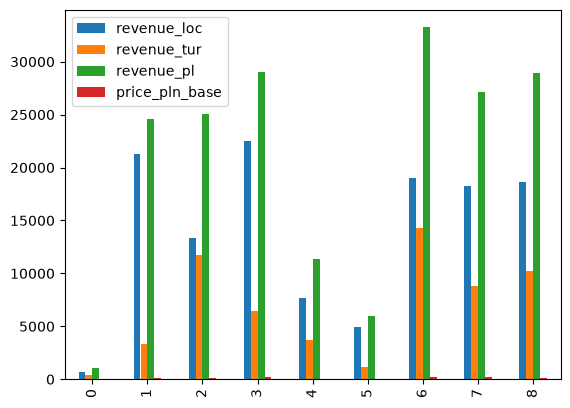

In [330]:
t1.plot.bar()

<Axes: >

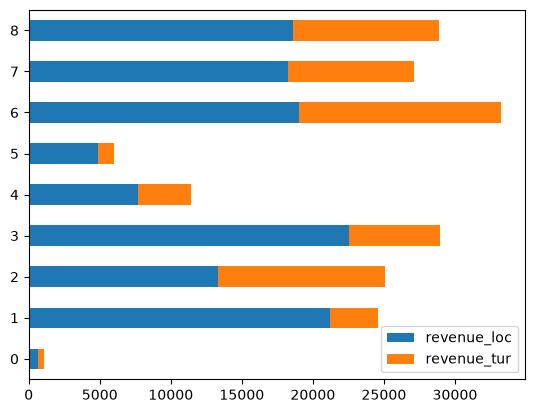

In [331]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

<BarContainer object of 9 artists>

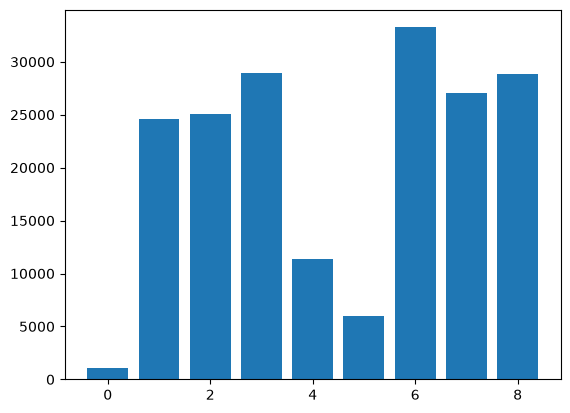

In [332]:
heights = t1["revenue_pl"]
plt.bar(range(len(heights)), heights)

In [333]:
heights = t1["revenue_pl"]
categories = t1["category"]

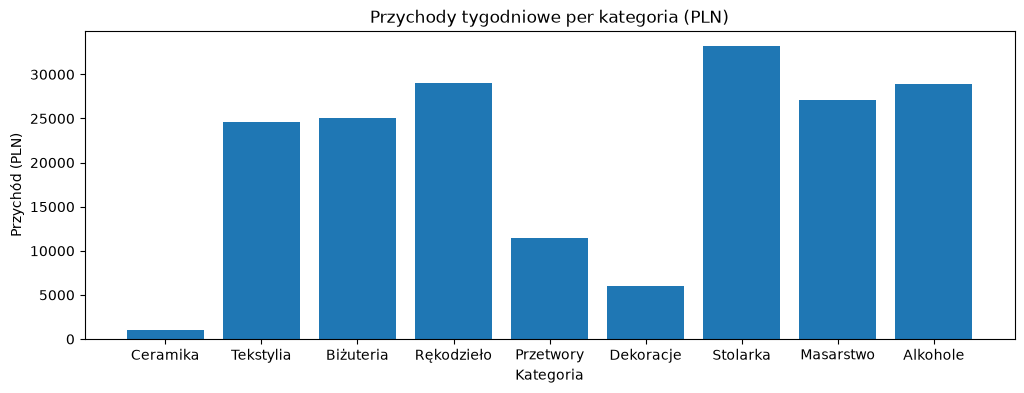

In [334]:
plt.figure(figsize=(12,4))
plt.title("Przychody tygodniowe per kategoria (PLN)")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.bar(categories, heights)
plt.show()

Etykiety wartości i formatowanie liczb